# 1, Calculation

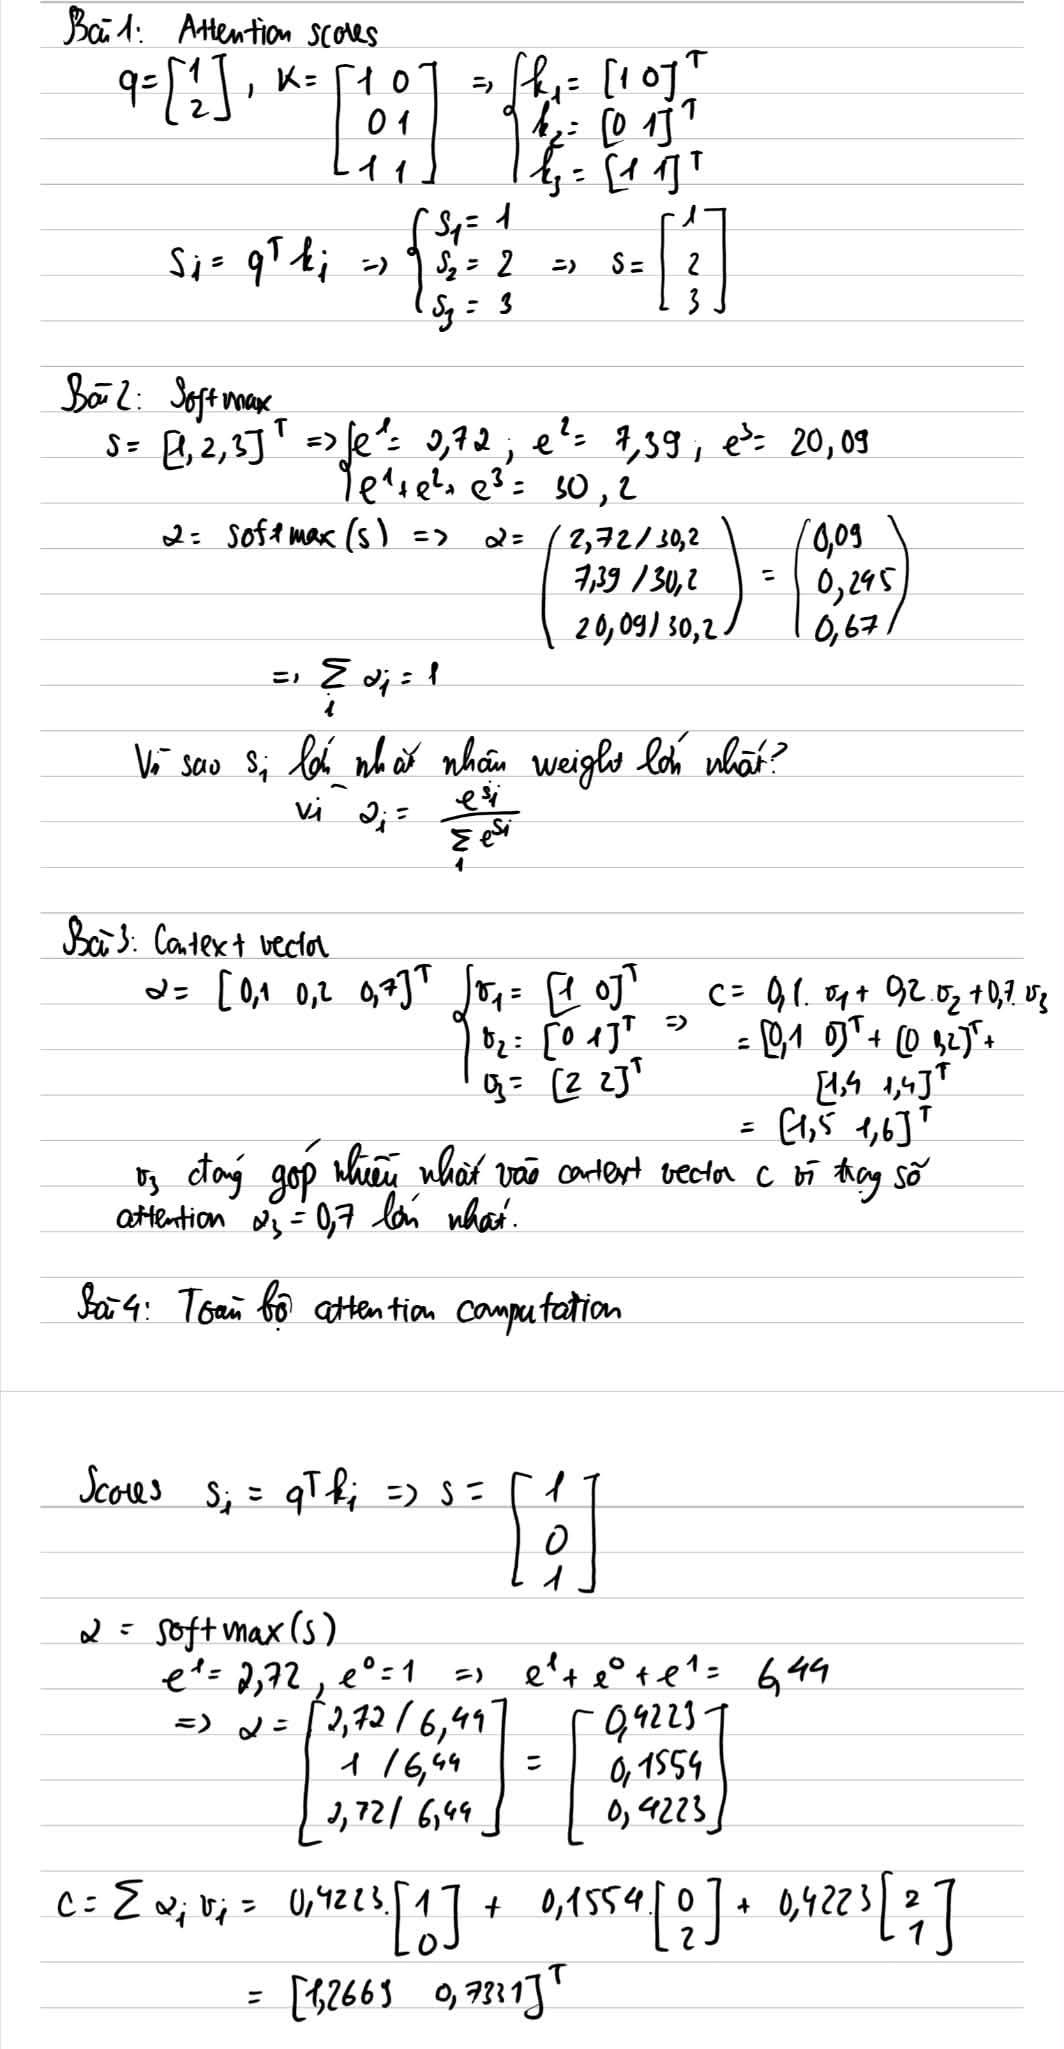

# 2, Prediction

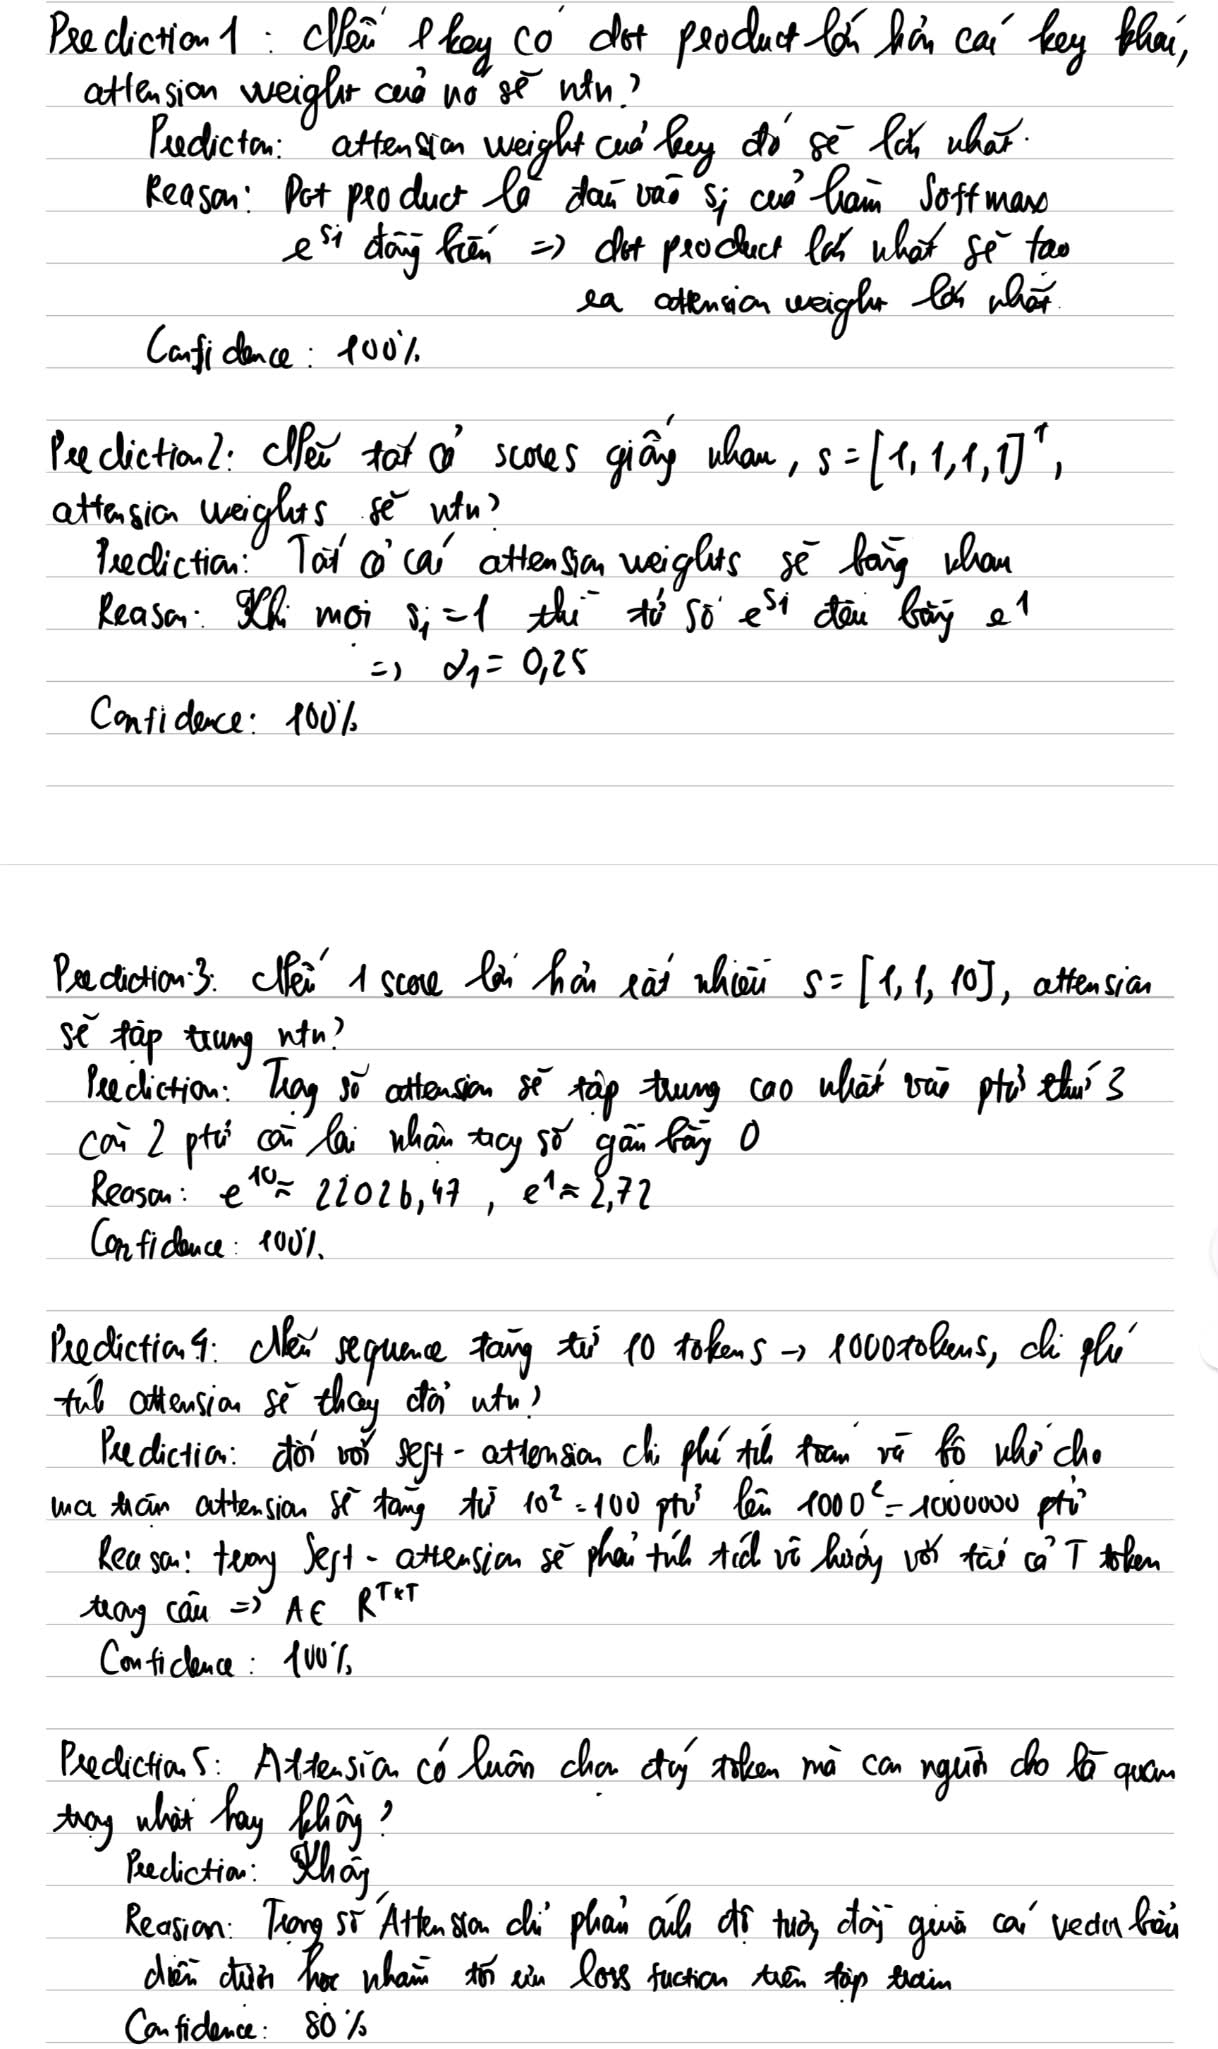

# 3, Attention implementation

In [1]:
%cd /content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/lab06

/content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/lab06


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def stable_softmax(x):
  x_shifted = x - np.max(x, axis=-1, keepdims=True)
  exp_x = np.exp(x_shifted)
  return exp_x / np.sum(exp_x, axis=-1, keepdims=True)


x_test = np.array([1000, 1001, 1002])
print(
    "Softmax ổn định với [1000, 1001, 1002]:",
    np.round(stable_softmax(x_test), 4),
)


def scaled_dot_product_attention(Q, K, V):
  d_k = K.shape[-1]
  scores = (Q @ K.T) / np.sqrt(d_k)
  attention_weights = stable_softmax(scores)
  context = attention_weights @ V
  return scores, attention_weights, context

Softmax ổn định với [1000, 1001, 1002]: [0.09   0.2447 0.6652]


In [3]:
tokens_exp1 = [
    "The",
    "movie",
    "was",
    "surprisingly",
    "good",
    "despite",
    "a",
    "very",
    "slow",
    "beginning",
]

np.random.seed(42)
K_exp1 = np.random.randn(len(tokens_exp1), 4)
V_exp1 = np.random.randn(len(tokens_exp1), 4)

EXPERIMENT 1


,Token,Score,Attention
0,The,0.4732,0.1569
1,movie,0.6349,0.1844
2,was,-0.3803,0.0668
3,surprisingly,-0.4663,0.0613
4,good,-0.7185,0.0477
5,despite,0.3448,0.1380
6,a,-0.5888,0.0542
7,very,-0.2691,0.0747
8,slow,0.3704,0.1416
9,beginning,-0.2732,0.0744


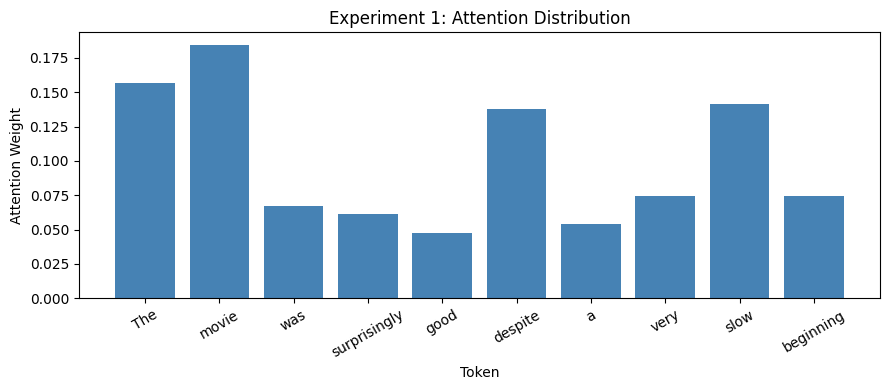

In [4]:
q_sim = np.array([[0.5, -0.2, 0.8, 0.1]])
scores_1, weights_1, context_1 = scaled_dot_product_attention(
    q_sim, K_exp1, V_exp1
)

df_exp1 = pd.DataFrame({
    "Token": tokens_exp1,
    "Score": np.round(scores_1[0], 4),
    "Attention": np.round(weights_1[0], 4),
})
print("EXPERIMENT 1")
display(df_exp1)

plt.figure(figsize=(9, 4))
plt.bar(tokens_exp1, weights_1[0], color="steelblue")
plt.title("Experiment 1: Attention Distribution")
plt.xlabel("Token")
plt.ylabel("Attention Weight")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [5]:

# Giả lập vector biểu diễn: chiều 0 đặc trưng cho Sentiment, chiều 1 đặc trưng cho Topic
K_exp2 = np.array([
    [0.1, 0.2, 0.0, 0.1],  # The
    [0.1, 2.5, 0.1, 0.0],  # movie (Topic cao)
    [0.0, 0.1, 0.2, 0.1],  # was
    [1.8, 0.2, 0.1, 0.0],  # surprisingly (Sentiment cao)
    [2.6, 0.3, 0.1, 0.0],  # good (Sentiment rất cao)
    [0.2, 0.1, 0.3, 0.1],  # despite
    [0.0, 0.1, 0.0, 0.1],  # a
    [0.5, 0.1, 0.2, 0.0],  # very
    [1.9, 0.2, 0.1, 0.0],  # slow (Sentiment cao)
    [0.2, 1.8, 0.1, 0.0],  # beginning (Topic cao)
])

query_A_sentiment = np.array([[2.0, 0.0, 0.0, 0.0]])
query_B_topic = np.array([[0.0, 2.0, 0.0, 0.0]])

_, weights_A, _ = scaled_dot_product_attention(query_A_sentiment, K_exp2, V_exp1)
_, weights_B, _ = scaled_dot_product_attention(query_B_topic, K_exp2, V_exp1)

df_exp2 = pd.DataFrame({
    "Token": tokens_exp1,
    "Attention (Query A - Sentiment)": np.round(weights_A[0], 4),
    "Attention (Query B - Topic)": np.round(weights_B[0], 4),
})
print(
    "\n EXPERIMENT 2: So sánh khi thay đổi Query"
)
display(df_exp2)


 EXPERIMENT 2: So sánh khi thay đổi Query


,Token,Attention (Query A - Sentiment),Attention (Query B - Topic)
0,The,0.0320,0.0441
1,movie,0.0320,0.4403
2,was,0.0290,0.0399
3,surprisingly,0.1753,0.0441
4,good,0.3902,0.0488
5,despite,0.0354,0.0399
6,a,0.0290,0.0399
7,very,0.0478,0.0399
8,slow,0.1938,0.0441
9,beginning,0.0354,0.2187


Nhận xét: Query A tập trung vào 'good', 'slow', 'surprisingly'; Query B tập trung vào 'movie', 'beginning'.

# 4, Self-Attention Implementation

In [6]:
tokens_sa = ["I", "like", "cats"]

X_sa = np.array([
    [1.0, 0.0],  # "I"
    [0.5, 1.5],  # "like"
    [0.0, 2.0],  # "cats"
])

W_Q = np.array([[1.0, 0.0], [0.0, 1.0]])
W_K = np.array([[1.0, 0.5], [0.5, 1.0]])
W_V = np.array([[0.5, 1.0], [1.0, 0.5]])

Q_sa = X_sa @ W_Q
K_sa = X_sa @ W_K
V_sa = X_sa @ W_V

QKT_sa = Q_sa @ K_sa.T

scores_sa, attn_matrix_sa, context_sa = scaled_dot_product_attention(
    Q_sa, K_sa, V_sa
)

print("Ma trận Q:\n", Q_sa)
print("\nMa trận K:\n", K_sa)
print("\nMa trận V:\n", V_sa)
print("\nMa trận QK^T:\n", QKT_sa)
print(
    "\nMa trận Attention Weights:\n", np.round(attn_matrix_sa, 4)
)
print(
    "\nContextual Representations (Output):\n", np.round(context_sa, 4)
)

Ma trận Q:
 [[1.  0. ]
 [0.5 1.5]
 [0.  2. ]]

Ma trận K:
 [[1.   0.5 ]
 [1.25 1.75]
 [1.   2.  ]]

Ma trận V:
 [[0.5  1.  ]
 [1.75 1.25]
 [2.   1.  ]]

Ma trận QK^T:
 [[1.   1.25 1.  ]
 [1.25 3.25 3.5 ]
 [1.   3.5  4.  ]]

Ma trận Attention Weights:
 [[0.3131 0.3737 0.3131]
 [0.0998 0.4104 0.4898]
 [0.0658 0.3854 0.5488]]

Contextual Representations (Output):
 [[1.4369 1.0934]
 [1.7477 1.1026]
 [1.805  1.0963]]


# 5, Scaling / temperature experiment

In [7]:
d_k_scale = 4
qkt_raw = np.array([4.0, 2.0, 0.0])
qkt_scaled = qkt_raw / np.sqrt(d_k_scale)

weights_unscaled = stable_softmax(qkt_raw)
weights_scaled = stable_softmax(qkt_scaled)

print("BÀI TẬP SCALING")
print("Unscaled scores:", qkt_raw, "-> Softmax:", np.round(weights_unscaled, 4))
print("Scaled scores:  ", qkt_scaled, "-> Softmax:", np.round(weights_scaled, 4))

BÀI TẬP SCALING
Unscaled scores: [4. 2. 0.] -> Softmax: [0.8668 0.1173 0.0159]
Scaled scores:   [2. 1. 0.] -> Softmax: [0.6652 0.2447 0.09  ]


In [8]:
s_temp = np.array([2.0, 1.0, 0.0])
temperatures = [0.5, 1.0, 2.0]
temp_rows = []

for T in temperatures:
  w = stable_softmax(s_temp / T)
  max_w = np.max(w)
  entropy = -np.sum(w * np.log(w + 1e-12))

  temp_rows.append({
      "Temperature": T,
      "Weights": np.round(w, 4).tolist(),
      "Max weight": round(float(max_w), 4),
      "Entropy": round(float(entropy), 4),
  })

df_temp = pd.DataFrame(temp_rows)
print("\n BẢNG THỰC NGHIỆM TEMPERATURE")
display(df_temp)


 BẢNG THỰC NGHIỆM TEMPERATURE


,Temperature,Weights,Max weight,Entropy
0,0.5,"[0.8668, 0.1173, 0.0159]",0.8668,0.4411
1,1.0,"[0.6652, 0.2447, 0.09]",0.6652,0.8324
2,2.0,"[0.5065, 0.3072, 0.1863]",0.5065,1.0202


T = 0.5 < 1: Phân phối nhọn (tập trung mạnh vào phần tử lớn nhất)

T = 1: Phân phối Softmax tiêu chuẩn (cân bằng)

T = 2 > 1: Phân phối phẳng hơn (chia đều sự chú ý hơn)

Scaling làm thay đổi độ tập trung của softmax như thế nào?

- phép chia $\sqrt{d_k}$ ngăn chặn hiện tượng Softmax bị bão hòa (saturation) và tránh triệt tiêu đạo hàm (vanishing gradients) khi số chiều $d_k$ lớn.

# 6, Attention visualization

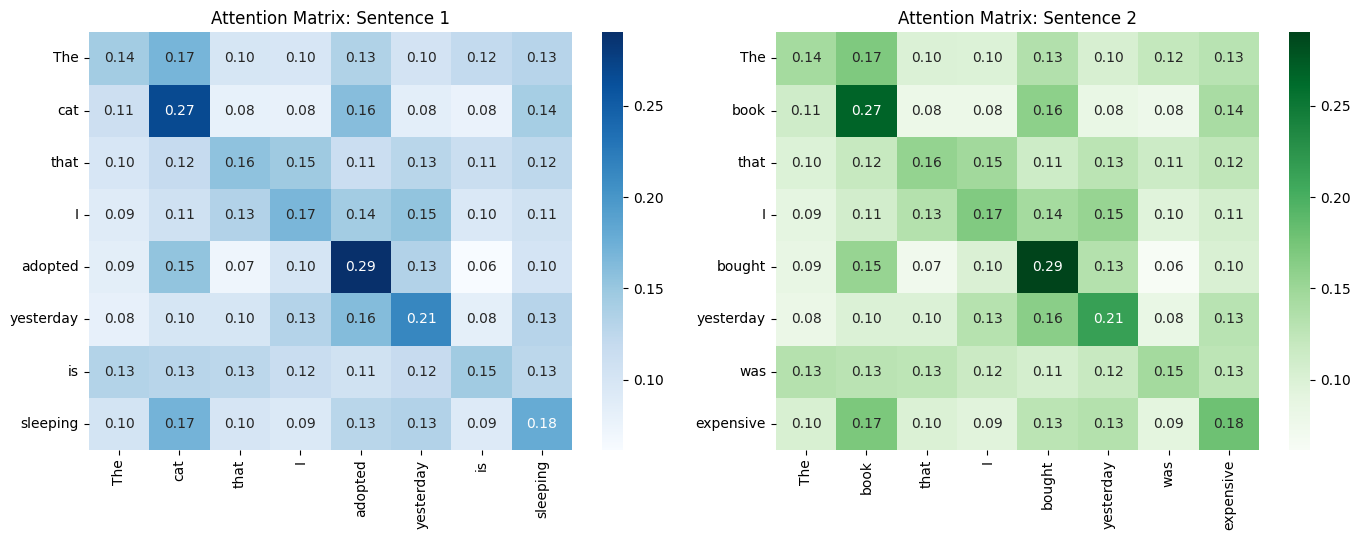

QUAN SÁT 3 TOKEN TRONG CÂU 1 ('cat', 'adopted', 'sleeping')
- Token 'cat' chú ý nhiều nhất tới: cat (0.27), adopted (0.16), sleeping (0.14)
- Token 'adopted' chú ý nhiều nhất tới: adopted (0.29), cat (0.15), yesterday (0.13)
- Token 'sleeping' chú ý nhiều nhất tới: sleeping (0.18), cat (0.17), yesterday (0.13)


In [9]:
import seaborn as sns


def build_semantic_self_attention(sentence):
  tokens = sentence.replace(".", "").split()
  T = len(tokens)
  np.random.seed(7)
  X = np.random.randn(T, 8) * 0.3

  # Tạo liên kết đặc trưng ngữ nghĩa cho các cụm danh từ - mệnh đề quan hệ - động từ chính
  for i, tok in enumerate(tokens):
    if tok in ["cat", "book", "adopted", "bought", "sleeping", "expensive"]:
      X[i, 0] += 1.5  # Nhóm chủ ngữ chính & vị ngữ/hành động liên quan
    if tok in ["I", "adopted", "bought", "yesterday"]:
      X[i, 1] += 1.2  # Nhóm mệnh đề phụ (người thực hiện & thời gian)

  _, attn_weights, _ = scaled_dot_product_attention(X, X, X)
  return tokens, attn_weights


sent1 = "The cat that I adopted yesterday is sleeping."
sent2 = "The book that I bought yesterday was expensive."

tokens1, attn1 = build_semantic_self_attention(sent1)
tokens2, attn2 = build_semantic_self_attention(sent2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(
    attn1,
    xticklabels=tokens1,
    yticklabels=tokens1,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title("Attention Matrix: Sentence 1")

sns.heatmap(
    attn2,
    xticklabels=tokens2,
    yticklabels=tokens2,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    ax=axes[1],
)
axes[1].set_title("Attention Matrix: Sentence 2")

plt.tight_layout()
plt.savefig(
    "attention_heatmap.png", dpi=150
)
plt.show()

print(
    "QUAN SÁT 3 TOKEN TRONG CÂU 1 ('cat', 'adopted', 'sleeping')"
)
for target in ["cat", "adopted", "sleeping"]:
  idx = tokens1.index(target)
  top_indices = np.argsort(attn1[idx])[::-1][:3]
  top_info = [f"{tokens1[j]} ({attn1[idx, j]:.2f})" for j in top_indices]
  print(f"- Token '{target}' chú ý nhiều nhất tới: {', '.join(top_info)}")

# 7, Application & 8, Quantitative evaluation

In [10]:
from collections import Counter
import re
import time
from datasets import load_dataset
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

imdb = load_dataset("stanfordnlp/imdb", name="plain_text")



train_data = imdb["train"].shuffle(seed=42)
test_data = imdb["test"].shuffle(seed=42)


# Hàm tách từ (Tokenizer) đơn giản
def simple_tokenize(text):
  text = text.lower()
  text = re.sub(r"<br\s*/?>", " ", text)
  return re.findall(r"\b\w+\b", text)


# Xây dựng Vocabulary với 10,000 từ phổ biến nhất
counter = Counter()
for item in train_data:
  counter.update(simple_tokenize(item["text"]))

MAX_VOCAB = 10000
MAX_LEN = 128
vocab = {"<pad>": 0, "<unk>": 1}
for word, _ in counter.most_common(MAX_VOCAB - 2):
  vocab[word] = len(vocab)


def encode_text(text, max_len=MAX_LEN):
  tokens = simple_tokenize(text)[:max_len]
  ids = [vocab.get(t, 1) for t in tokens]
  if len(ids) < max_len:
    ids += [0] * (max_len - len(ids))
  return ids

In [11]:
X_train = torch.tensor([encode_text(x["text"]) for x in train_data], dtype=torch.long)
y_train = torch.tensor([x["label"] for x in train_data], dtype=torch.float32)
X_test = torch.tensor([encode_text(x["text"]) for x in test_data], dtype=torch.long)
y_test = torch.tensor([x["label"] for x in test_data], dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=64, shuffle=False)
print(f"X_train {X_train.shape}, X_test {X_test.shape}")

X_train torch.Size([25000, 128]), X_test torch.Size([25000, 128])


In [12]:
# LSTM sử dụng Final Hidden State
class LSTMClassifier(nn.Module):

  def __init__(self, vocab_size, embed_dim=64, hidden_dim=64):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
    self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
    self.fc = nn.Linear(hidden_dim, 1)

  def forward(self, x):
    emb = self.embedding(x)
    _, (h_n, _) = self.lstm(emb)
    final_hidden = h_n[-1]
    logits = self.fc(final_hidden).squeeze(-1)
    return logits


# Self-Attention Classifier
class SelfAttentionClassifier(nn.Module):

  def __init__(self, vocab_size, embed_dim=64):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
    self.W_Q = nn.Linear(embed_dim, embed_dim, bias=False)
    self.W_K = nn.Linear(embed_dim, embed_dim, bias=False)
    self.W_V = nn.Linear(embed_dim, embed_dim, bias=False)
    self.fc = nn.Linear(embed_dim, 1)

  def forward(self, x, return_attn=False):
    mask = x != 0
    emb = self.embedding(x)

    Q = self.W_Q(emb)
    K = self.W_K(emb)
    V = self.W_V(emb)

    d_k = K.size(-1)
    scores = torch.bmm(Q, K.transpose(1, 2)) / (d_k**0.5)

    scores = scores.masked_fill(~mask.unsqueeze(1), -1e9)
    attn_weights = torch.softmax(scores, dim=-1)

    context_seq = torch.bmm(attn_weights, V)  8, Quantitative evaluation

    mask_float = mask.unsqueeze(-1).float()
    context_vector = (context_seq * mask_float).sum(dim=1) / mask_float.sum(
        dim=1
    ).clamp(min=1e-9)

    logits = self.fc(context_vector).squeeze(-1)
    if return_attn:
      return logits, attn_weights
    return logits

In [13]:
def train_and_evaluate(model, name, epochs=5):
  model = model.to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
  criterion = nn.BCEWithLogitsLoss()

  num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

  start_time = time.time()
  for epoch in range(epochs):
    model.train()
    for bx, by in train_loader:
      bx, by = bx.to(device), by.to(device)
      optimizer.zero_grad()
      out = model(bx)
      loss = criterion(out, by)
      loss.backward()
      optimizer.step()
  train_time = time.time() - start_time

  model.eval()
  all_preds, all_probs, all_labels = [], [], []
  with torch.no_grad():
    for bx, by in test_loader:
      bx = bx.to(device)
      logits = model(bx)
      probs = torch.sigmoid(logits).cpu().numpy()
      preds = (probs >= 0.5).astype(int)
      all_probs.extend(probs)
      all_preds.extend(preds)
      all_labels.extend(by.numpy().astype(int))

  acc = accuracy_score(all_labels, all_preds)
  f1 = f1_score(all_labels, all_preds)

  return {
      "Model": name,
      "Accuracy": round(acc, 4),
      "F1": round(f1, 4),
      "Training time (s)": round(train_time, 2),
      "Parameters": num_params,
  }, all_preds, all_probs, all_labels

EXPERIMENT 4


,Model,Accuracy,F1,Training time (s),Parameters
0,LSTM,0.8040,0.8043,7.24,673345
1,Attention,0.8223,0.8148,6.18,652353


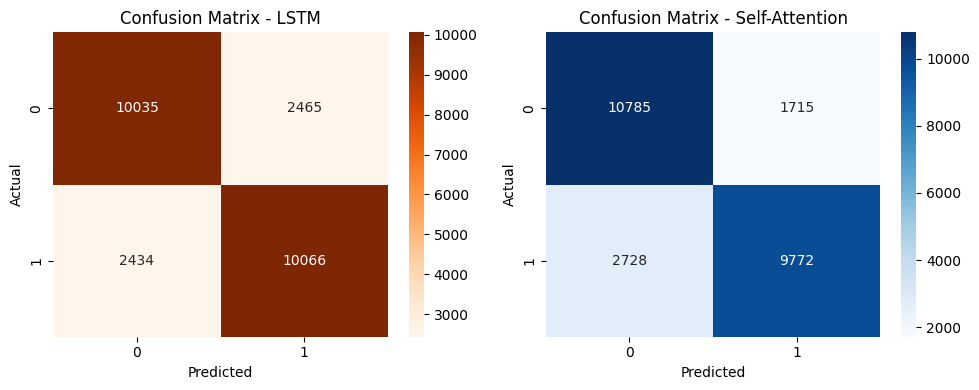

In [14]:
lstm_model = LSTMClassifier(len(vocab))
attn_model = SelfAttentionClassifier(len(vocab))

res_lstm, preds_lstm, _, labels_test = train_and_evaluate(
    lstm_model, "LSTM", epochs=5
)
res_attn, preds_attn, probs_attn, _ = train_and_evaluate(
    attn_model, "Attention", epochs=5
)

df_results = pd.DataFrame([res_lstm, res_attn])
df_results.to_csv("results.csv", index=False)
print("EXPERIMENT 4")
display(df_results)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
cm_lstm = confusion_matrix(labels_test, preds_lstm)
cm_attn = confusion_matrix(labels_test, preds_attn)

sns.heatmap(cm_lstm, annot=True, fmt="d", cmap="Oranges", ax=axes[0])
axes[0].set_title("Confusion Matrix - LSTM")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_attn, annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("Confusion Matrix - Self-Attention")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

Representation của hai model khác nhau ở đâu?

- LSTM: Biểu diễn câu bằng trạng thái ẩn cuối cùng ($h_T$), được cập nhật tuần tự qua từng bước thời gian $t = 1 \dots T$. Thông tin ở đầu câu dễ bị mai một khi câu dài, nhưng mô hình nắm bắt tốt thứ tự từ cục bộ (local word order).

- Self-Attention: Biểu diễn câu bằng tổ hợp có trọng số (weighted combination) trực tiếp từ tất cả các vị trí trong chuỗi mà không cần đi qua các bước trung gian tuần tự. Nhờ đó, nó gom trực tiếp các từ mang sắc thái cảm xúc mạnh ở bất kỳ vị trí nào trong câu và tính toán song song nhanh hơn nhiều trên GPU.

In [17]:
print("EXPERIMENT 5")
seq_lengths = [10, 100, 500, 1000, 10000]
cost_rows = []
for T in seq_lengths:
  cost_rows.append({
      "Sequence length (T)": T,
      "Attention matrix shape": f"({T} x {T})",
      "Số phần tử (T^2)": f"{T**2:,}",
      "Bộ nhớ ước tính (Float32 - MB)": round((T**2 * 4) / (1024**2), 2),
  })
df_cost = pd.DataFrame(cost_rows)
display(df_cost)

EXPERIMENT 5


,Sequence length (T),Attention matrix shape,Số phần tử (T^2),Bộ nhớ ước tính (Float32 - MB)
0,10,(10 x 10),100,0.00
1,100,(100 x 100),"10,000",0.04
2,500,(500 x 500),"250,000",0.95
3,1000,(1000 x 1000),"1,000,000",3.81
4,10000,(10000 x 10000),"100,000,000",381.47


Tại sao self-attention có vấn đề computational cost khi sequence rất dài?

- Vì Self-Attention phải tính điểm tương đồng giữa mọi cặp token $(i, j)$ trong chuỗi độ dài $T$, tạo ra ma trận kích thước $T \times T$ có độ phức tạp thời gian và bộ nhớ là $O(T^2)$. Khi $T$ tăng từ $100$ lên $1,000$ hay $10,000$, số phần tử tăng vọt từ $10,000$ lên $1,000,000$ và $100,000,000$ phần tử, gây tràn bộ nhớ VRAM (Out-Of-Memory) trên các văn bản dài.

Câu 1: 'I like this movie.'
 -> Prediction: Negative (0) | Probability (Positive): 0.0214
 -> Trọng số Attention theo token: {'i': np.float32(0.122), 'like': np.float32(0.569), 'this': np.float32(0.105), 'movie': np.float32(0.204)} 

Câu 2: 'I do not like this movie.'
 -> Prediction: Negative (0) | Probability (Positive): 0.0027
 -> Trọng số Attention theo token: {'i': np.float32(0.088), 'do': np.float32(0.14), 'not': np.float32(0.132), 'like': np.float32(0.413), 'this': np.float32(0.086), 'movie': np.float32(0.14)} 

Câu 3: 'I thought this movie would be bad, but it was actually excellent.'
 -> Prediction: Positive (1) | Probability (Positive): 0.6478
 -> Trọng số Attention theo token: {'i': np.float32(0.031), 'thought': np.float32(0.088), 'this': np.float32(0.039), 'movie': np.float32(0.027), 'would': np.float32(0.049), 'be': np.float32(0.084), 'bad': np.float32(0.265), 'but': np.float32(0.024), 'it': np.float32(0.049), 'was': np.float32(0.046), 'actually': np.float32(0.057), 'excell

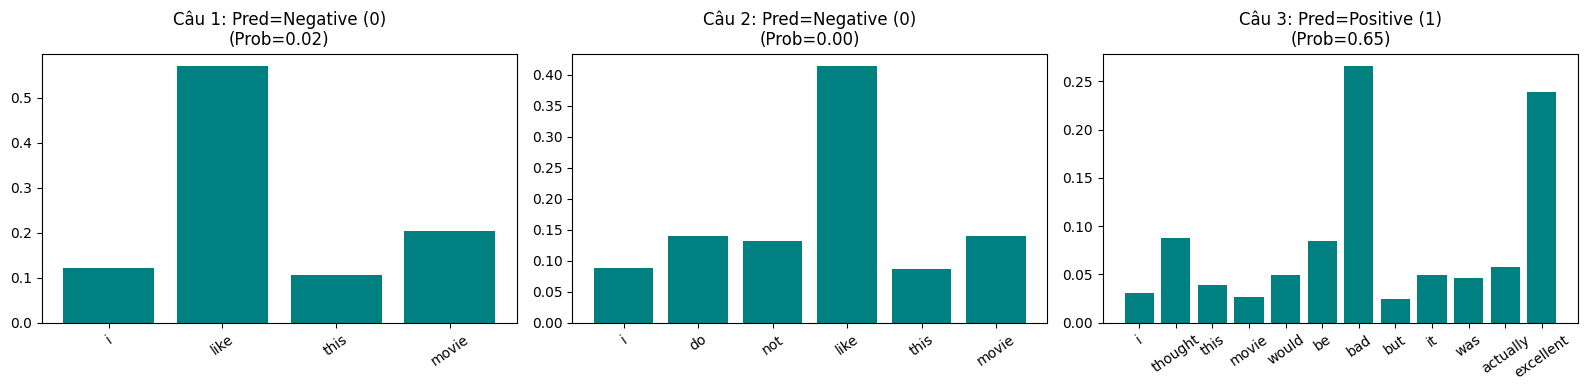

In [20]:
# Application

test_sentences = [
    "I like this movie.",
    "I do not like this movie.",
    "I thought this movie would be bad, but it was actually excellent.",
]

attn_model.eval()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for idx, sent in enumerate(test_sentences):
  tokens = simple_tokenize(sent)
  ids = [vocab.get(t, 1) for t in tokens]
  x_tensor = torch.tensor([ids], dtype=torch.long, device=device)

  with torch.no_grad():
    logit, attn_w = attn_model(x_tensor, return_attn=True)
    prob = torch.sigmoid(logit).item()
    pred_label = "Positive (1)" if prob >= 0.5 else "Negative (0)"

  token_importance = attn_w[0].mean(dim=0).cpu().numpy()

  print(f"Câu {idx+1}: '{sent}'")
  print(
      f" -> Prediction: {pred_label} | Probability (Positive): {prob:.4f}"
  )
  print(
      " -> Trọng số Attention theo token:",
      dict(zip(tokens, np.round(token_importance, 3))),
      "\n",
  )

  axes[idx].bar(tokens, token_importance, color="teal")
  axes[idx].set_title(f"Câu {idx+1}: Pred={pred_label}\n(Prob={prob:.2f})")
  axes[idx].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

# 9, Error analysis

In [22]:
correct_samples = []
incorrect_samples = []

attn_model.eval()
for i in range(len(test_data)):
  true_y = labels_test[i]
  pred_y = preds_attn[i]
  prob_y = probs_attn[i]
  raw_text = test_data[i]["text"]

  tokens = simple_tokenize(raw_text)[:MAX_LEN]
  x_in = X_test[i : i + 1].to(device)
  with torch.no_grad():
    _, attn_w = attn_model(x_in, return_attn=True)
  valid_len = len(tokens)
  tok_weights = attn_w[0, :valid_len, :valid_len].mean(dim=0).cpu().numpy()
  top_idx = np.argsort(tok_weights)[::-1][:5]
  top_tokens = [f"{tokens[j]} ({tok_weights[j]:.3f})" for j in top_idx]

  info = {
      "Index": i,
      "True Label": true_y,
      "Pred Label": pred_y,
      "Prob": round(float(prob_y), 4),
      "Top Attended Tokens": ", ".join(top_tokens),
      "Text Snippet": raw_text[:220] + "...",
  }

  if true_y == pred_y and len(correct_samples) < 3:
    correct_samples.append(info)
  elif true_y != pred_y and len(incorrect_samples) < 3:
    incorrect_samples.append(info)

  if len(correct_samples) == 3 and len(incorrect_samples) == 3:
    break

print("3 MẪU DỰ ĐOÁN ĐÚNG")
display(pd.DataFrame(correct_samples))

print("\n 3 MẪU DỰ ĐOÁN SAI")
display(pd.DataFrame(incorrect_samples))

3 MẪU DỰ ĐOÁN ĐÚNG


,Index,True Label,Pred Label,Prob,Top Attended Tokens,Text Snippet
0,0,1,1,0.9314,"superbly (0.058), started (0.050), laura (0.04...",<br /><br />When I unsuspectedly rented A Thou...
1,1,1,1,0.6200,"1950 (0.046), seriously (0.030), stand (0.028)...",This is the latest entry in the long series of...
2,2,0,0,0.1525,"girl (0.076), bad (0.052), horrible (0.038), f...",This movie was so frustrating. Everything seem...



 3 MẪU DỰ ĐOÁN SAI


,Index,True Label,Pred Label,Prob,Top Attended Tokens,Text Snippet
0,6,1,0,0.3103,"unbelievable (0.056), badly (0.053), touching ...","This is a really sad, and touching movie! It d..."
1,8,0,1,0.5484,"low (0.063), enjoyable (0.046), tedious (0.038...",Porn legend Gregory Dark directs this cheesy h...
2,22,0,1,0.7910,"sequel (0.021), tribute (0.020), existed (0.02...","In the early 00's, production companies had a ..."
